In [3]:

from pathlib import Path
import sys
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = NOTEBOOK_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
SRC_DIR = PROJECT_DIR / "src"

sys.path.insert(0, str(SRC_DIR))

from perceptron import Perceptron
from adaline import ADALINE

train_data = pd.read_csv(DATA_DIR / "train.csv")
validation_data = pd.read_csv(DATA_DIR / "validation.csv")
test_data = pd.read_csv(DATA_DIR / "test.csv")

X_train = train_data.drop(
    columns=["risk", "final_result", "id_student"],
    errors="ignore"
)
y_train = train_data["risk"].astype(int).to_numpy()

X_validation = validation_data.drop(
    columns=["risk", "final_result", "id_student"],
    errors="ignore"
)
y_validation = validation_data["risk"].astype(int).to_numpy()

X_test = test_data.drop(
    columns=["risk", "final_result", "id_student"],
    errors="ignore"
)
y_test = test_data["risk"].astype(int).to_numpy()

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = [
    column for column in X_train.columns
    if column not in categorical_features
]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        categorical_features
    )
])

X_train_processed = preprocessor.fit_transform(X_train)
X_validation_processed = preprocessor.transform(X_validation)
X_test_processed = preprocessor.transform(X_test)

print("DATA LOADED AND PREPROCESSED")
print("Training:", X_train_processed.shape)
print("Validation:", X_validation_processed.shape)
print("Test:", X_test_processed.shape)
print("Training labels:", np.unique(y_train))

DATA LOADED AND PREPROCESSED
Training: (22815, 59)
Validation: (4889, 59)
Test: (4889, 59)
Training labels: [0 1]


In [4]:

# Train Perceptron
perceptron_model = Perceptron(
    learning_rate=0.01,
    epochs=100
)

perceptron_model.fit(X_train_processed, y_train)

print("Perceptron training completed!")

# Train ADALINE
adaline_model = ADALINE(
    learning_rate=0.0001,
    epochs=100
)

adaline_model.fit(X_train_processed, y_train)

print("ADALINE training completed!")

Perceptron training completed!
ADALINE training completed!


In [5]:

models = {
    "Perceptron": perceptron_model,
    "ADALINE": adaline_model
}

validation_results = []

for model_name, model in models.items():
    predictions = model.predict(X_validation_processed)

    accuracy = accuracy_score(y_validation, predictions)
    precision = precision_score(
        y_validation, predictions, zero_division=0
    )
    recall = recall_score(
        y_validation, predictions, zero_division=0
    )
    f1 = f1_score(
        y_validation, predictions, zero_division=0
    )

    validation_results.append({
        "Model": model_name,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4)
    })

    print(f"\n===== {model_name} =====")
    print("Confusion Matrix:")
    print(confusion_matrix(y_validation, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_validation, predictions, zero_division=0
    ))

validation_results_df = pd.DataFrame(validation_results)

print("\n===== VALIDATION COMPARISON =====")
display(validation_results_df)


===== Perceptron =====
Confusion Matrix:
[[1842  466]
 [ 608 1973]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.80      0.77      2308
           1       0.81      0.76      0.79      2581

    accuracy                           0.78      4889
   macro avg       0.78      0.78      0.78      4889
weighted avg       0.78      0.78      0.78      4889


===== ADALINE =====
Confusion Matrix:
[[ 351 1957]
 [1635  946]]

Classification Report:
              precision    recall  f1-score   support

           0       0.18      0.15      0.16      2308
           1       0.33      0.37      0.35      2581

    accuracy                           0.27      4889
   macro avg       0.25      0.26      0.25      4889
weighted avg       0.26      0.27      0.26      4889


===== VALIDATION COMPARISON =====


,Model,Accuracy,Precision,Recall,F1 Score
0,Perceptron,0.7803,0.8089,0.7644,0.7861
1,ADALINE,0.2653,0.3259,0.3665,0.3450


In [6]:

test_results = []

test_models = {
    "Perceptron": perceptron_model,
    "ADALINE": adaline_model
}

for model_name, model in test_models.items():
    predictions = model.predict(X_test_processed)

    test_results.append({
        "Model": model_name,
        "Accuracy": round(
            accuracy_score(y_test, predictions), 4
        ),
        "Precision": round(
            precision_score(y_test, predictions, zero_division=0), 4
        ),
        "Recall": round(
            recall_score(y_test, predictions, zero_division=0), 4
        ),
        "F1 Score": round(
            f1_score(y_test, predictions, zero_division=0), 4
        )
    })

    print(f"\n===== {model_name}: TEST RESULTS =====")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

test_results_df = pd.DataFrame(test_results)

print("\n===== FINAL TEST COMPARISON =====")
display(test_results_df)

RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

test_results_df.to_csv(
    RESULTS_DIR / "perceptron_adaline_test_results.csv",
    index=False
)

print("\nResults saved to:")
print(RESULTS_DIR / "perceptron_adaline_test_results.csv")


===== Perceptron: TEST RESULTS =====
Confusion Matrix:
[[1820  488]
 [ 585 1996]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.79      0.77      2308
           1       0.80      0.77      0.79      2581

    accuracy                           0.78      4889
   macro avg       0.78      0.78      0.78      4889
weighted avg       0.78      0.78      0.78      4889


===== ADALINE: TEST RESULTS =====
Confusion Matrix:
[[ 383 1925]
 [1655  926]]

Classification Report:
              precision    recall  f1-score   support

           0       0.19      0.17      0.18      2308
           1       0.32      0.36      0.34      2581

    accuracy                           0.27      4889
   macro avg       0.26      0.26      0.26      4889
weighted avg       0.26      0.27      0.26      4889


===== FINAL TEST COMPARISON =====


,Model,Accuracy,Precision,Recall,F1 Score
0,Perceptron,0.7805,0.8035,0.7733,0.7882
1,ADALINE,0.2677,0.3248,0.3588,0.3409



Results saved to:
c:\Users\devas\Downloads\Academic-Intervention-System-main\Academic-Intervention-System-main\results\perceptron_adaline_test_results.csv


In [7]:

# Combine test results from all three models

ann_results_path = RESULTS_DIR / "ann_test_results.csv"
perceptron_adaline_path = (
    RESULTS_DIR / "perceptron_adaline_test_results.csv"
)

print("Available result files:")
for file in RESULTS_DIR.glob("*.csv"):
    print(file.name)

if ann_results_path.exists():
    ann_results_df = pd.read_csv(ann_results_path)

    print("\nANN results loaded:")
    display(ann_results_df)

    combined_results_df = pd.concat(
        [ann_results_df, test_results_df],
        ignore_index=True
    )

    combined_results_df.to_csv(
        RESULTS_DIR / "all_models_comparison.csv",
        index=False
    )

    print("\nCombined comparison saved:")
    print(RESULTS_DIR / "all_models_comparison.csv")

    display(combined_results_df)

else:
    print(
        "\nANN test results CSV not found at the expected path."
    )
    print(
        "We will create the combined comparison after checking "
        "the actual ANN results file."
    )

Available result files:
perceptron_adaline_test_results.csv

ANN test results CSV not found at the expected path.
We will create the combined comparison after checking the actual ANN results file.


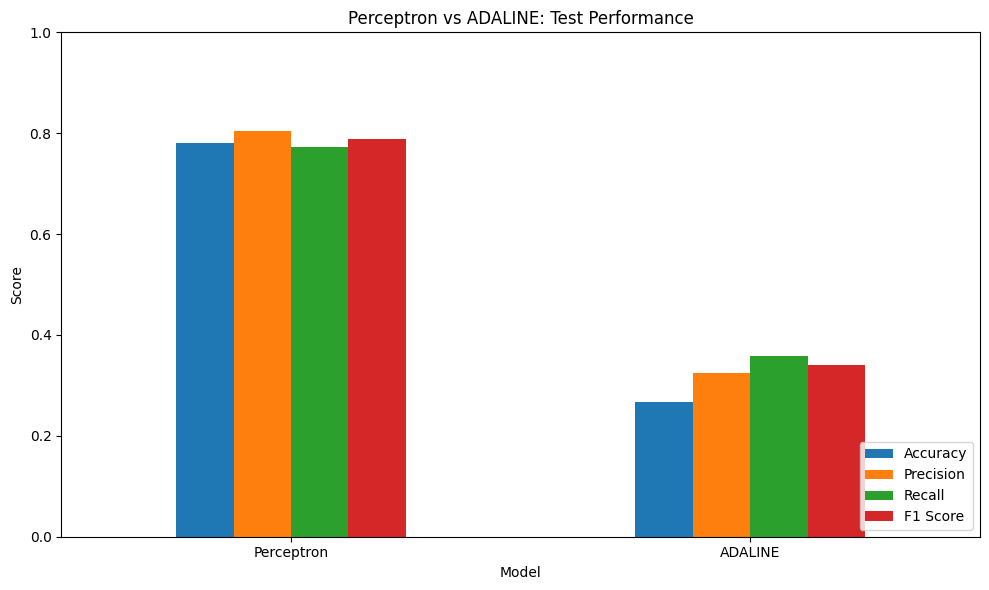

Comparison graph saved to:
c:\Users\devas\Downloads\Academic-Intervention-System-main\Academic-Intervention-System-main\results\perceptron_adaline_comparison.png


In [8]:

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

ax = test_results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("Perceptron vs ADALINE: Test Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

graph_path = RESULTS_DIR / "perceptron_adaline_comparison.png"

fig = ax.get_figure()
fig.savefig(graph_path, dpi=300, bbox_inches="tight")

print("Comparison graph saved to:")
print(graph_path)

In [9]:
import joblib

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(perceptron_model, MODELS_DIR / "perceptron_model.pkl")
joblib.dump(adaline_model, MODELS_DIR / "adaline_model.pkl")

print("Perceptron model saved successfully!")
print("ADALINE model saved successfully!")
print("Models folder:", MODELS_DIR)

Perceptron model saved successfully!
ADALINE model saved successfully!
Models folder: c:\Users\devas\Downloads\Academic-Intervention-System-main\Academic-Intervention-System-main\models
